# 06 · Comparison with a purely hydraulic approach - Table 12 and Fig. 11

Section 3.7: Lee et al. (1997) only match **flow rates**. First, the cooler equations give the
water flow rate each cooler would need to meet its set-point with the current hot stream flow
rates (water supply temperature fixed at 32 °C). Then a purely hydraulic problem minimizes the
sum of squared deviations between cooler flow rates and these targets, with the same budget as
Case 1A. The thermal model is used afterwards only to *evaluate* the economic penalties.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import paper_case
from coolingnet.optimization import SolverSettings
from coolingnet.reporting import figures as F
from coolingnet.reporting import paper_reference as REF
from coolingnet.reporting import tables as T
from coolingnet.reporting.tables import flow_deviation
from coolingnet.workflow import PaperPipeline, PipelineConfig

RESULTS_DIR = Path("../results")
FORCE_RESOLVE = False

case = paper_case()
pipeline = PaperPipeline(case, PipelineConfig(results_dir=RESULTS_DIR, force=FORCE_RESOLVE, solver=SolverSettings(name="nlpbb", time_limit_s=900)))
sims = pipeline.run_simulations()
lit = pipeline.run_literature()
desired, hydraulic = lit["desired_flows"], lit["hydraulic_only"]
print("hydraulic-only run:", hydraulic.report["termination"], f"budget = {hydraulic.budget} USD/y")

hydraulic-only run: optimal budget = 2625.0 USD/y


## Table 12

In [2]:
table12 = T.table_hydraulic_only(sims["current"], desired, hydraulic)
display(table12.round(3))
display(REF.compare(REF.TABLE12, table12.drop(index="Total")).round(3))

,Current cooling water flow rate (kg/s),Desired cooling water flow rate (kg/s),Optimal cooling water flow rate (kg/s),Valve head loss (m),Penalty (kUSD/y)
E-101,11.917,11.356,4.414,6.048,36.809
E-102,28.848,52.235,33.042,0.000,13.654
E-103,35.567,46.220,39.247,0.000,13.372
E-104,15.529,21.227,14.283,2.587,24.068
E-105,3.229,3.163,0.020,6.348,341.764
Total,95.090,134.201,91.006,NaN,429.667


,Current cooling water flow rate (kg/s) [paper],Current cooling water flow rate (kg/s) [this work],Desired cooling water flow rate (kg/s) [paper],Desired cooling water flow rate (kg/s) [this work],Optimal cooling water flow rate (kg/s) [paper],Optimal cooling water flow rate (kg/s) [this work],Valve head loss (m) [paper],Valve head loss (m) [this work],Penalty (kUSD/y) [paper],Penalty (kUSD/y) [this work]
Heat exchanger,,,,,,,,,,
E-101,11.92,11.917,11.36,11.356,4.410,4.414,7.14,6.048,36.90,36.809
E-102,28.85,28.848,52.24,52.235,33.030,33.042,0.00,0.000,13.72,13.654
E-103,35.57,35.567,46.22,46.220,39.230,39.247,0.00,0.000,13.51,13.372
E-104,15.53,15.529,21.23,21.227,14.280,14.283,2.58,2.587,24.19,24.068
E-105,3.23,3.229,3.16,3.163,0.073,0.020,6.42,6.348,320.00,341.764


In [3]:
targets = {x["tag"]: x["k_kg_s"] for x in desired.exchangers}
dev_current = flow_deviation(sims["current"], targets)
dev_optimal = flow_deviation(hydraulic, targets)
pd.DataFrame(
    {
        "this work": [dev_current, dev_optimal, hydraulic.costs["cpen"] / 1e3],
        "paper": [REF.LEE_FLOW_DEVIATION["current_kg2_s2"], REF.LEE_FLOW_DEVIATION["optimal_kg2_s2"], REF.TABLE12_TOTALS["penalty"]],
    },
    index=["sum of squared flow deviations, current (kg2/s2)", "sum of squared flow deviations, optimal (kg2/s2)", "total penalty of the hydraulic solution (kUSD/y)"],
).round(1)

,this work,paper
"sum of squared flow deviations, current (kg2/s2)",693.3,696.8
"sum of squared flow deviations, optimal (kg2/s2)",523.3,524.0
total penalty of the hydraulic solution (kUSD/y),429.7,408.3


## Fig. 11 - pipe diameters after the purely hydraulic optimization

The purely hydraulic solution keeps the existing pump and reaches a lower flow-rate gap, but its
economic performance is very poor: E-105 is almost starved of cooling water, which brings a huge
penalty. Planning interventions requires the complete model (tower + network + coolers +
economics).

pump: {'2': '1'} | pipes changed: {'1': 24.0, '10': 16.0, '13': 0.5, '14': 2.5, '15': 18.0, '18': 0.5}
paper: {'pump': '1', 'pipes_changed': {'1': 24.0, '10': 16.0, '15': 18.0}}


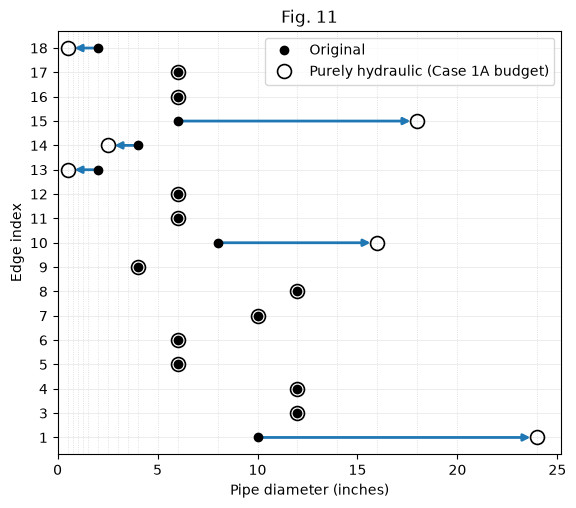

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
F.plot_diameter_dotchart(case, hydraulic, ax=ax, label="Purely hydraulic (Case 1A budget)", title="Fig. 11")
fig.savefig("../figures/fig11_diameters_hydraulic_only.png", dpi=150, bbox_inches="tight")
print("pump:", hydraulic.pump_options(), "| pipes changed:", {str(e["id"]): e["diameter_in"] for e in hydraulic.edges if e.get("changed")})
print("paper:", REF.LEE_DESIGN)